# Module 6 — Evaluation as a deploy gate, runnable

**The problem.** 'It looks good' is not evaluation. The architect decides **what good means, numerically, before building**, measures it on a **golden set**, and wires the result into CI as a **gate that blocks the deploy** — not a dashboard someone glances at. And one number is never enough: a system can ace answer-quality (L2) and still fail the business outcome (L3).

Three layers, measured here: **L1 component** (retrieval recall@k), **L2 quality** (faithfulness / answer-correctness), **L3 business** (containment / escalation). Plus the gate, judge **calibration**, and a canary. The faithfulness judge is a stand-in for RAGAS / an NLI model, **calibrated, not trusted blind** (the lesson from M5). Needs Ollama (`qwen2.5:7b`, `bge-m3`).


## 0. Setup


In [1]:
import sys, pathlib, importlib, re, json as _json, statistics
here = pathlib.Path.cwd()
for p in (here, here/"notebooks", here.parent):
    if (p/"arch_kit.py").exists(): sys.path.insert(0, str(p)); break
import arch_kit; importlib.reload(arch_kit)
from arch_kit import embed, cosine, chat
print("ready —", arch_kit.CHAT_MODEL, "via", arch_kit.OLLAMA)


ready — qwen2.5:7b via http://127.0.0.1:11434


## 1. Define 'good' before you build — the golden set with numeric thresholds

A golden set is labelled examples with **categories** (so you can see per-slice failure), the expected answer, and a human grounding label. Thresholds are **numbers, not adjectives** — 'faithfulness ≥ 0.85', never 'high quality'. Write them before the first line of the component.

**Caveat on size:** a *real* golden set is hundreds of cases per category. This toy n=6 is for illustration, and at n=6 the thresholds are coarse — 'faithfulness ≥ 0.85' means *zero misses* (the only reachable values are 0, 0.17, … 0.83, 1.0), while 'answer_correct ≥ 0.80' tolerates one. Set thresholds **with the set size in mind**: at small n a single flaky judge call flips the gate.


In [2]:
DOCS = {
 "retention": "The data-retention policy keeps access logs for 18 months, then purges them.",
 "leave":     "Annual leave is 25 days; carry-over of up to 5 days is allowed until March.",
 "hotline":   "The incident hotline is staffed 24/7; the escalation SLA is 15 minutes.",
 "expense":   "Expense claims over 500 CHF require a second approver in the finance tool.",
 "vpn":       "The VPN disconnects idle sessions after 30 minutes for security.",
 "refund":    "Refunds are issued within 14 days to the original payment method.",
}
# golden set: question, category, the doc that should be retrieved, a substring the answer must contain,
# and a HUMAN grounding label (did a person judge the ideal answer grounded?) -- used to calibrate the judge.
GOLDEN = [
 {"q":"How long are access logs kept?",          "cat":"policy", "gold":"retention", "want":"18 months",     "human_grounded":True},
 {"q":"How many annual leave days do we get?",   "cat":"policy", "gold":"leave",     "want":"25",            "human_grounded":True},
 {"q":"What is the incident escalation SLA?",     "cat":"policy", "gold":"hotline",   "want":"15 minutes",    "human_grounded":True},
 {"q":"How are refunds paid out?",                "cat":"policy", "gold":"refund",    "want":"14 days",       "human_grounded":True},
 {"q":"Who must approve a 2000 CHF expense?",      "cat":"edge",   "gold":"expense",   "want":"second approver","human_grounded":True},
 {"q":"When does the VPN drop an idle session?",  "cat":"edge",   "gold":"vpn",       "want":"30 minutes",    "human_grounded":True},
]
THRESHOLDS = {"recall@3": 0.80, "faithfulness": 0.85, "answer_correct": 0.80, "containment": 0.70}
print(f"golden set: {len(GOLDEN)} cases across categories {sorted({g['cat'] for g in GOLDEN})}")
print("thresholds (numeric, set BEFORE building):", THRESHOLDS)


golden set: 6 cases across categories ['edge', 'policy']
thresholds (numeric, set BEFORE building): {'recall@3': 0.8, 'faithfulness': 0.85, 'answer_correct': 0.8, 'containment': 0.7}


## 2. L1 — component metric: retrieval recall@k (per category, not just overall)

The cheapest layer: does retrieval even surface the right document? Measured with the real embedder, overall **and per category** — because an aggregate can hide a failing slice.


In [3]:
_DOC_VECS = {k: embed(v) for k, v in DOCS.items()}
def retrieve(q, k=3):
    qv = embed(q)
    return [d for d, _ in sorted(((d, cosine(qv, v)) for d, v in _DOC_VECS.items()),
                                 key=lambda kv: kv[1], reverse=True)[:k]]

def recall_at_k(items, k=3):
    hits = [1 if g["gold"] in retrieve(g["q"], k) else 0 for g in items]
    return sum(hits)/len(hits)

overall = recall_at_k(GOLDEN, 3)
print(f"recall@3 overall: {overall:.2f}")
for cat in sorted({g["cat"] for g in GOLDEN}):
    sub = [g for g in GOLDEN if g["cat"]==cat]
    print(f"  recall@3 [{cat:6}] : {recall_at_k(sub,3):.2f}  (n={len(sub)})")


recall@3 overall: 1.00
  recall@3 [edge  ] : 1.00  (n=2)


  recall@3 [policy] : 1.00  (n=4)


**Read it.** recall@k is the first gate: if the right document isn't retrieved, no amount of generation quality saves the answer. Reading it **per category** is the point — a healthy overall number *can* sit on top of a slice that fails. Here both slices pass (n=2 and n=4 — too small to reveal much); the failing-slice mechanism is shown with hand-set numbers in §6, where the gate blocks on the slice, not the average.


## 3. L2 — quality: faithfulness (judged) and answer-correctness (exact)

Given the retrieved context, is the generated answer **grounded** in it (faithfulness, judged by a model — calibrated in §5) and does it contain the **right fact** (answer-correctness, an exact check)? These are different: an answer can be faithful to the wrong chunk, or correct by luck.


In [4]:
def _supported(raw):   # pure, FAIL-CLOSED parser: unparseable -> not supported
    return raw.strip().upper().startswith("SUPPORTED")
def faithful_judge(answer, context):   # RAGAS/NLI stand-in; unparseable reply -> UNSUPPORTED (transport errors raise)
    return _supported(chat(f"CONTEXT:\n{context}\n\nANSWER: {answer}\n\nIs the ANSWER fully supported by the "
                           f"CONTEXT? Reply only SUPPORTED or UNSUPPORTED.", num_predict=5))

def rag_answer(q, k=3):
    ctx = "\n".join(DOCS[d] for d in retrieve(q, k))
    return chat(q, system="Answer in one short sentence using only the context.\n\nCONTEXT:\n"+ctx, num_predict=40), ctx

rows = []
for g in GOLDEN:
    ans, ctx = rag_answer(g["q"])
    f = faithful_judge(ans, ctx); c = g["want"].lower() in ans.lower()
    rows.append({**g, "ans": ans.strip(), "faith": f, "correct": c})
    print(f"[{g['cat']:6}] faithful={f!s:5} correct={c!s:5} want={g['want']!r:16} :: {ans.strip()[:46]}")
L2 = {"faithfulness": sum(r["faith"] for r in rows)/len(rows),
      "answer_correct": sum(r["correct"] for r in rows)/len(rows)}
print(f"\nL2: faithfulness={L2['faithfulness']:.2f}  answer_correct={L2['answer_correct']:.2f}")
# where the JUDGE disagrees with the human label (human said grounded + the fact is right, yet judge UNSUPPORTED)
disagree = [r for r in rows if r["human_grounded"] and r["correct"] and not r["faith"]]
for r in disagree:
    print(f"  !! judge DISAGREES with the human label (a judge false-negative): {r['ans'][:48]!r}")


[policy] faithful=True  correct=True  want='18 months'      :: Access logs are kept for 18 months.


[policy] faithful=True  correct=True  want='25'             :: We get 25 annual leave days.


[policy] faithful=True  correct=True  want='15 minutes'     :: The incident escalation SLA is 15 minutes.


[policy] faithful=True  correct=True  want='14 days'        :: Refunds are issued within 14 days to the origi


[edge  ] faithful=False correct=True  want='second approver' :: A second approver must approve a 2000 CHF expe


[edge  ] faithful=True  correct=True  want='30 minutes'     :: The VPN drops an idle session after 30 minutes

L2: faithfulness=0.83  answer_correct=1.00
  !! judge DISAGREES with the human label (a judge false-negative): 'A second approver must approve a 2000 CHF expens'


**Read it.** Faithfulness (judged) and answer-correctness (exact substring) are different axes — the first asks *is it supported by the context*, the second *does it contain the right fact*. The substring check is cheap but blunt: it over-counts negations ("not 25 days") and number-substrings ("25" inside "2025") and under-counts paraphrases ("a year and a half" for "18 months") — pick it knowing those failure modes. And watch the `!!` line: the judge marked a **correct, human-grounded** answer ("a second approver for a 2000 CHF expense", context says *over 500 CHF requires a second approver*) as UNSUPPORTED — a **judge false-negative**. That single miss is what drags faithfulness below our bar; §5 measures whether the judge can be trusted, and §6 shows what to do when a judge error blocks a release.


## 4. L3 — business outcome: you can ace L2 and still fail L3

The layer teams forget. A support assistant can answer *accurately* (high L2) and still not *resolve the user's need* (low L3 containment) — correct information that doesn't solve the problem, so the user escalates anyway. We use a small **constructed** ticket log (illustrative, not a measured product) to make the gap concrete.


In [5]:
# each ticket: did we answer CORRECTLY (an L2 property) and did it RESOLVE the user's need (the L3 outcome)?
TICKETS = [
 {"id":1, "answered_correct":True,  "resolved":True},    # correct AND solved
 {"id":2, "answered_correct":True,  "resolved":False},   # correct info, user still escalates (need not met)
 {"id":3, "answered_correct":True,  "resolved":False},
 {"id":4, "answered_correct":True,  "resolved":True},
 {"id":5, "answered_correct":False, "resolved":False},   # wrong and unresolved
]
accuracy    = sum(t["answered_correct"] for t in TICKETS)/len(TICKETS)   # an L2-style number
containment = sum(t["resolved"]        for t in TICKETS)/len(TICKETS)    # the L3 outcome
escalation  = 1 - containment
print(f"L2-style accuracy : {accuracy:.2f}")
print(f"L3 containment    : {containment:.2f}   (escalation {escalation:.2f})")
print(f"gap: the system is {accuracy:.0%} accurate but only {containment:.0%} of users got their need met")


L2-style accuracy : 0.80
L3 containment    : 0.40   (escalation 0.60)
gap: the system is 80% accurate but only 40% of users got their need met


**Read it.** Accuracy is high and containment is low: tickets 2 and 3 got a *correct* answer and the user escalated anyway — the answer didn't solve their actual problem (e.g. wrong channel, missing action, needed a human; `TICKETS` only records resolved/not, not the reason). If you gate only on L2 you ship a system that looks great and doesn't work. L3 is 'is it solving the problem?', and it can only be measured against real outcomes (containment, straight-through processing, conversion), not against the model's own answers.


## 5. The LLM judge is not ground truth — calibrate it against humans first

Before you gate on a model-judged metric, measure how often the judge **agrees with a human**. A judge at 70% agreement is a weak gate; you need to know the number, not assume it.


In [6]:
# calibration set: (answer, context, HUMAN label). Mix grounded + fabricated, like M5.
CAL = [
 ("Access logs are kept for 18 months.",                         DOCS["retention"], True),
 ("Records are retained for a year and a half before deletion.", DOCS["retention"], True),   # true paraphrase
 ("Access logs are kept for 10 years and sold to partners.",     DOCS["retention"], False),  # fabricated
 ("Access logs are kept for 18 days.",                           DOCS["retention"], False),  # one-word false
 ("Annual leave is 25 days.",                                    DOCS["leave"],     True),
 ("Annual leave is unlimited.",                                  DOCS["leave"],     False),
 ("A second approver must approve a 2000 CHF expense.",
  "\n".join(DOCS[d] for d in retrieve("Who must approve a 2000 CHF expense?")), True),   # SAME top-3 context §3 judged -> reproduces the miss
]
agree = sum(1 for ans, ctx, human in CAL if faithful_judge(ans, ctx) == human)
print(f"judge agreement with human labels: {agree}/{len(CAL)} = {agree/len(CAL):.0%}  (n={len(CAL)})")
print("n=7 is far too small to trust a 0.85 bar -- you'd want hundreds of labelled cases per failure mode.")
print("calibration only covers the failure modes IN the set; the numeric-entailment case is the one §3 tripped on.")


judge agreement with human labels: 6/7 = 86%  (n=7)
n=7 is far too small to trust a 0.85 bar -- you'd want hundreds of labelled cases per failure mode.
calibration only covers the failure modes IN the set; the numeric-entailment case is the one §3 tripped on.


**Read it.** The agreement number is the judge's licence to be a gate — and read it against §3: the numeric-entailment case (2000 > 500) is one the judge gets **wrong**, the very miss that dragged §3's faithfulness down, so agreement here is **not** 100%. High agreement → you can automate with spot re-checks; low → the judge is noise and a human stays in the loop. Either way you must *know* the number — treating an uncalibrated LLM-judge as ground truth is the named anti-pattern (gating on a ruler you never measured). And n=7 can't establish a rate; a real calibration set is hundreds of cases per failure mode.


## 6. The gate — block the deploy, per category, on any breached threshold

Eval is a **gate, not a report**: a breach returns a non-zero exit and blocks the release. And it checks **each category**, because a single aggregate hides a failing slice.


In [7]:
def eval_gate(metrics, per_category, thresholds):
    breaches = []
    for name, val in metrics.items():
        if name in thresholds and val < thresholds[name]:
            breaches.append(f"{name} {val:.2f} < {thresholds[name]}")
    for (metric, cat), val in per_category.items():
        if metric in thresholds and val < thresholds[metric]:
            breaches.append(f"{metric}[{cat}] {val:.2f} < {thresholds[metric]}")
    return (len(breaches) == 0), breaches

# recall@3/faithfulness/answer_correct are MEASURED on the golden run; containment comes from the
# (constructed) ticket log, NOT from this run -- the gate just combines whatever metrics it is given.
metrics = {"recall@3": overall, **L2, "containment": containment}
per_cat = {("recall@3", c): recall_at_k([g for g in GOLDEN if g["cat"]==c], 3)
           for c in sorted({g["cat"] for g in GOLDEN})}
ok, breaches = eval_gate(metrics, per_cat, THRESHOLDS)
print("release metrics:", {k: round(v,2) for k,v in metrics.items()})
print("GATE:", "PASS -> merge" if ok else "BLOCK -> candidate cannot merge", "| breaches:", breaches or "none")

# why PER-CATEGORY matters -- HAND-SET numbers to show the mechanism (not a measurement):
demo_metrics  = {"recall@3": 0.84}
demo_per_cat  = {("recall@3","policy"): 0.95, ("recall@3","edge"): 0.50}
ok2, br2 = eval_gate(demo_metrics, demo_per_cat, {"recall@3": 0.80})
print(f"\n[hand-set demo] aggregate-only PASSES (0.84 >= 0.80); per-category gate: {'PASS' if ok2 else 'BLOCK'} -> {br2}")


release metrics: {'recall@3': 1.0, 'faithfulness': 0.83, 'answer_correct': 1.0, 'containment': 0.4}
GATE: BLOCK -> candidate cannot merge | breaches: ['faithfulness 0.83 < 0.85', 'containment 0.40 < 0.7']

[hand-set demo] aggregate-only PASSES (0.84 >= 0.80); per-category gate: BLOCK -> ['recall@3[edge] 0.50 < 0.8']


**Read it — carefully, because this run's breaches are the real lesson.** `faithfulness 0.83 < 0.85` is the **judge's false-negative** from §3 (a correct, human-grounded answer it misjudged), and `containment 0.40` is a **constructed** number from the ticket log — *neither is a measured defect of this release*. The honest response to a disputed block is to **fix the judge (or the golden label) and re-run — never lower the bar after seeing the result**, which is exactly what §1 forbids. (It also shows the gate *working*: it refuses to wave anything through, including when the ruler is the thing that's wrong — that's why you calibrate the ruler in §5.) The hand-set second run is the other lesson: an aggregate recall of 0.84 sails past a 0.80 bar while the `edge` slice sits at 0.50 — gate on the slices, not the average.


## 7. Drift / canary — catch a regression the metrics would miss between releases

A canary is a fixed input with a known-good property, re-run continuously. If a new model version (or a prompt tweak) breaks it, you find out immediately, not from users. (The regression below is **simulated** by wrapping the output.)


In [8]:
CANARY = {"prompt": "Reply with exactly the word: OK", "ok": lambda o: o.strip().upper() == "OK"}
def model_current(x):   return chat(x, num_predict=5)
def model_regressed(x): return "Sure thing! " + chat(x, num_predict=5)   # SIMULATED regression (wraps the output)

cur = model_current(CANARY["prompt"]); reg = model_regressed(CANARY["prompt"])
cur_ok, reg_ok = CANARY["ok"](cur), CANARY["ok"](reg)
print(f"current   canary: {cur.strip()[:30]!r}  format-ok={cur_ok}")
print(f"regressed canary: {reg.strip()[:30]!r}  format-ok={reg_ok}" + ("" if reg_ok else "  <- caught before users saw it"))


current   canary: 'OK'  format-ok=True
regressed canary: 'Sure thing! OK'  format-ok=False  <- caught before users saw it


### The eval gate in CI


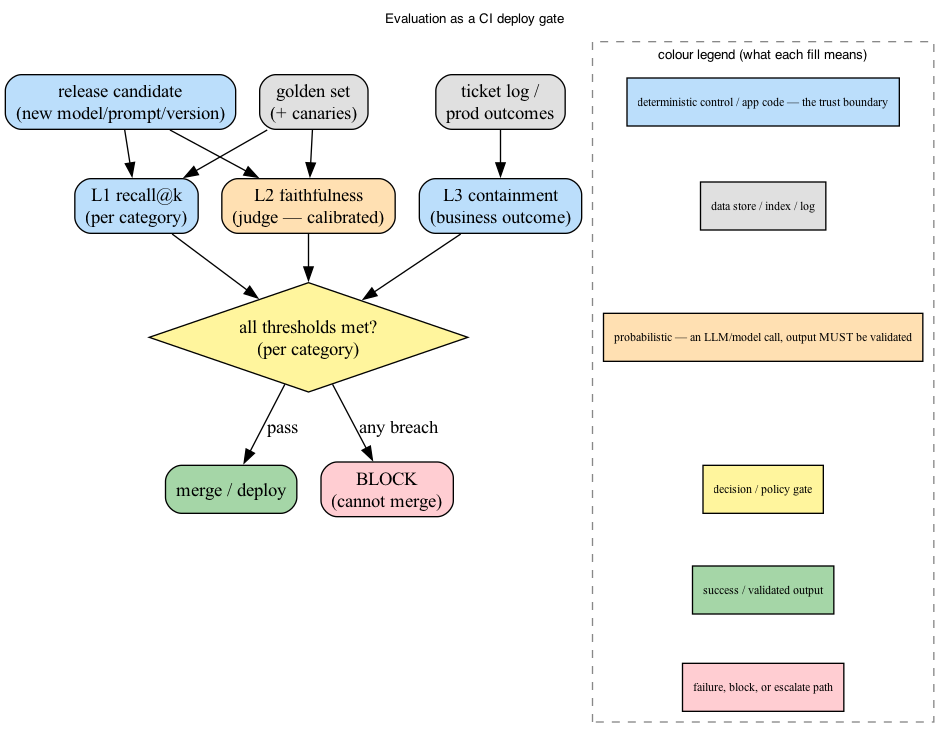

In [9]:
from graphviz import Digraph
from IPython.display import Image, display
from arch_kit import dnode, diagram_legend
g = Digraph(); g.attr(rankdir="TB", fontname="Helvetica", fontsize="10", labelloc="t",
                      label="Evaluation as a CI deploy gate")
dnode(g,"pr","release candidate\n(new model/prompt/version)","control")
dnode(g,"gold","golden set\n(+ canaries)","data")
dnode(g,"tix","ticket log /\nprod outcomes","data")
dnode(g,"l1","L1 recall@k\n(per category)","control")
dnode(g,"l2","L2 faithfulness\n(judge — calibrated)","model")
dnode(g,"l3","L3 containment\n(business outcome)","control")
dnode(g,"gate","all thresholds met?\n(per category)","gate")
dnode(g,"deploy","merge / deploy","ok")
dnode(g,"block","BLOCK\n(cannot merge)","fail")
g.edge("pr","l1"); g.edge("pr","l2"); g.edge("gold","l1"); g.edge("gold","l2"); g.edge("tix","l3")
g.edge("l1","gate"); g.edge("l2","gate"); g.edge("l3","gate")
g.edge("gate","deploy",label="pass"); g.edge("gate","block",label="any breach")
diagram_legend(g, ["control","data","model","gate","ok","fail"])
try: display(Image(g.pipe(format="png")))
except Exception as e: print("diagram render skipped (needs the graphviz 'dot' binary):", e)


## 8. Meaningful tests

Deterministic eval guarantees — the judge-dependent faithfulness is reported, not asserted.


In [10]:
def run_checks():
    checks=[]
    def check(n,c,w): checks.append((n,"PASS" if c else "FAIL",w))

    # recall@k is computed correctly on a controlled case
    check("recall@k = 1.0 when the gold doc is in top-k, < 1.0 when it isn't",
          recall_at_k([{"q":"How long are access logs kept?","cat":"x","gold":"retention","want":""}],3)==1.0
          and recall_at_k([{"q":"How long are access logs kept?","cat":"x","gold":"refund","want":""}],1) < 1.0,
          "the component metric must actually reflect whether the right doc was retrieved")
    # the gate BLOCKS on a per-category breach even when the aggregate passes
    ok2,_ = eval_gate({"recall@3":0.84}, {("recall@3","edge"):0.50}, {"recall@3":0.80})
    check("per-category gate blocks a failing slice an aggregate would hide",
          ok2 is False,
          "a single aggregate metric hiding a per-category failure is the named anti-pattern")
    # the gate PASSES only when every metric and slice meets threshold
    ok3,_ = eval_gate({"recall@3":0.9}, {("recall@3","policy"):0.9,("recall@3","edge"):0.9}, {"recall@3":0.80})
    check("gate passes only when all metrics and slices meet threshold",
          ok3 is True,
          "green must mean every slice met the bar, not just the average")
    # the faithfulness parser fails CLOSED on unparseable output
    check("the faithfulness parser fails CLOSED (empty/garbled -> not supported)",
          _supported("")==False and _supported("i think so?")==False and _supported("SUPPORTED")==True,
          "a judge that can't parse its own verdict must not count as 'supported'")
    # the gate blocks specifically on a faithfulness breach (any configured threshold)
    check("the gate blocks on a faithfulness breach",
          eval_gate({"faithfulness":0.80}, {}, {"faithfulness":0.85})[0] is False,
          "a breach of any configured threshold must block, not merely warn")
    # canary check passes known-good and fails a regressed format
    check("the canary check passes known-good and fails a regressed format",
          CANARY["ok"]("OK") and not CANARY["ok"]("Sure thing! OK"),
          "a fixed known-good check flags a regression before users do")

    import pandas as pd
    print(pd.DataFrame(checks, columns=["check","result","why it matters"]).to_string(index=False))
    assert all(r=="PASS" for _,r,_ in checks), "an evaluation guarantee broke"
    print("\nall", len(checks), "meaningful checks passed")
run_checks()


                                                                check result                                                                    why it matters
    recall@k = 1.0 when the gold doc is in top-k, < 1.0 when it isn't   PASS    the component metric must actually reflect whether the right doc was retrieved
     per-category gate blocks a failing slice an aggregate would hide   PASS a single aggregate metric hiding a per-category failure is the named anti-pattern
          gate passes only when all metrics and slices meet threshold   PASS                     green must mean every slice met the bar, not just the average
the faithfulness parser fails CLOSED (empty/garbled -> not supported)   PASS            a judge that can't parse its own verdict must not count as 'supported'
                             the gate blocks on a faithfulness breach   PASS                  a breach of any configured threshold must block, not merely warn
      the canary check passes known-good and f

## Check your understanding

**Q1.** Why set the numeric thresholds *before* building the component, not after seeing the first results?
<details><summary>answer</summary>Because a threshold set after you've seen the output is a threshold drawn around whatever you got — it rationalises the result instead of judging it. Deciding 'faithfulness ≥ 0.85, recall@3 ≥ 0.80' up front, with 'what good looks like' on representative cases, turns evaluation into a test the system must pass, not a story you tell about the numbers afterwards.</details>

**Q2.** A system scores 92% answer-accuracy (L2) but 40% containment (L3). Is it ready to ship?
<details><summary>answer</summary>No — and this is the whole point of L3. Accurate answers that don't *resolve* the user's need (wrong channel, missing action, needed a human) leave 60% of users escalating. L2 measures whether the answer is right; L3 measures whether the problem got solved, and you can ace the first while failing the second. Ship on the business outcome, not the answer-quality proxy.</details>

**Q3.** The overall recall@3 is 0.84, above the 0.80 bar. Why might the gate still block?
<details><summary>answer</summary>Because the gate reads **per category**, and a slice (e.g. `edge` queries at 0.50) can fail while the average passes — the aggregate is carried by the easy majority. A gate that only checks the overall number ships the broken slice. The fix is to gate on every category, so a healthy average can't hide a failing segment.</details>

**Q4.** Why measure the LLM judge's agreement with humans before using it as a gate?
<details><summary>answer</summary>Because the judge *is* the ruler, and an unmeasured ruler can't be trusted. If it agrees with humans only 70% of the time, gating on it blocks good releases and passes bad ones at that error rate. You calibrate it against human labels first, gate on it only if the agreement is high enough, and re-check as the model/version changes — never treat its verdict as ground truth.</details>
